# Phase 3E.03 — Transaction Costs, Turnover & Net Performance

## 1. Research Objective

This notebook evaluates the economic impact of portfolio turnover
and transaction costs on the 12-month TSMOM strategy.

The analysis compares gross and net performance against the
Equal-Weighted Long-Only benchmark across Train and Validation.

The Test period remains untouched until Phase 3F.

In [2]:
from pathlib import Path
import sys

project_root = Path.cwd()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not (project_root / "src").is_dir():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import importlib
import src.data
import src.metrics
import src.research
import src.signals
import src.strategy

from matplotlib.ticker import PercentFormatter
from src.data import prepare_monthly_prices
from src.strategy import build_tsmom_positions, calculate_portfolio_weights, calculate_portfolio_exposure, calculate_gross_portfolio_returns
from src.metrics import calculate_performance_metrics

## 2. Data & Portfolio Setup

Reconstruct the 12-month TSMOM portfolio and its Equal-Weighted Long-Only benchmark using the existing research infrastructure.

$$
p_{i,t}=s_{i,t-1},\qquad w_{i,t}=\frac{p_{i,t}}{N},\quad N=16
$$

$$
r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1
$$

$$
R_{p,t}^{gross}=\sum_{i=1}^{N}w_{i,t}r_{i,t}
$$

$$
w_{i,t}^{B}=\frac{1}{N},\qquad R_{B,t}=\frac{1}{N}\sum_{i=1}^{N}r_{i,t}
$$

**Notation and implementation.** $i$ denotes an ETF, $t$ the holding month, $N=16$, $s_{i,t-1}$ the preceding month-end signal, and $P_{i,t}$ the adjusted month-end price. $p_{i,t}$ and $w_{i,t}$ correspond to `positions` and `portfolio_weights`; $r_{i,t}$ is `asset_returns`; $R_{p,t}^{gross}$ is `gross_portfolio_returns`. The benchmark uses $w_{i,t}^{B}$ (`benchmark_weights`) and $R_{B,t}$ (`benchmark_returns`).

In [3]:
asset_universe = {
    "Equities" : ["SPY", "VGK", "EWJ", "EEM"],
    "Commodities" : ["USO", "DBA", "DBB", "DBC"],
    "Bonds" : ["IEF", "TLT", "LQD", "HYG"],
    "Forex" : ["FXE", "FXY", "FXB", "FXA"]
}

tickers = []

for assets in asset_universe.values():
    tickers.extend(assets)

start_date = "2008-01-01"
end_date = "2022-01-01"
lookback = 12

monthly_prices = prepare_monthly_prices(tickers, start_date, end_date)

signals, positions = build_tsmom_positions(monthly_prices, lookback=lookback)

portfolio_weights = calculate_portfolio_weights(positions)

gross_exposure, net_exposure = calculate_portfolio_exposure(portfolio_weights)

print(monthly_prices.head())
print(monthly_prices.shape)

print(positions.head())
print(positions.shape)

print(portfolio_weights.dropna().head())
print(portfolio_weights.shape)

Ticker            DBA        DBB        DBC        EEM        EWJ        FXA  \
Date                                                                           
2008-01-31  31.200174  19.611864  27.033497  30.937828  36.718548  65.858292   
2008-02-29  35.054859  21.755016  30.046467  31.554817  36.170078  68.784676   
2008-03-31  30.744696  20.388252  29.771803  30.370564  35.708210  67.721046   
2008-04-30  30.871220  20.388252  31.569599  33.145889  38.335091  70.257103   
2008-05-31  29.816872  19.385418  33.750252  34.194557  39.085629  71.677834   

Ticker             FXB         FXE         FXY        HYG        IEF  \
Date                                                                   
2008-01-31  173.245651  136.197632   93.910004  30.854891  56.444138   
2008-02-29  173.586090  139.362106   96.129997  30.278128  57.143661   
2008-03-31  174.066666  145.244614  100.239998  30.564560  57.907806   
2008-04-30  175.017471  144.052933   95.949997  31.602816  56.507946   
2008-05

In [4]:
asset_returns, weighted_returns, gross_portfolio_returns = calculate_gross_portfolio_returns(monthly_prices, portfolio_weights)

print(asset_returns.head())
print(asset_returns.shape)

print(weighted_returns.head())
print(weighted_returns.shape)

print(gross_portfolio_returns.dropna().head())
print(gross_portfolio_returns.shape)

Ticker           DBA       DBB       DBC       EEM       EWJ       FXA  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.123547  0.109278  0.111453  0.019943 -0.014937  0.044435   
2008-03-31 -0.122955 -0.062825 -0.009141 -0.037530 -0.012769 -0.015463   
2008-04-30  0.004115  0.000000  0.060386  0.091382  0.073565  0.037449   
2008-05-31 -0.034153 -0.049187  0.069074  0.031638  0.019578  0.020222   

Ticker           FXB       FXE       FXY       HYG       IEF       LQD  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.001965  0.023234  0.023640 -0.018693  0.012393 -0.007063   
2008-03-31  0.002769  0.042210  0.042755  0.009460  0.013372 -0.005972   
2008-04-30  0.005462 -0.008205 -0.042797  0.033969 -0.024174  0.012447   
2008-05-31  0.000468 -0.000180 -0.013

In [5]:
benchmark_weights = pd.DataFrame(1/len(portfolio_weights.columns), index=portfolio_weights.index, columns=portfolio_weights.columns)

print(benchmark_weights.head())

benchmark_returns = (asset_returns * benchmark_weights).sum(axis=1, min_count=16)

print(benchmark_returns.head())
print(benchmark_returns.shape)

Ticker         DBA     DBB     DBC     EEM     EWJ     FXA     FXB     FXE  \
Date                                                                         
2008-01-31  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625   
2008-02-29  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625   
2008-03-31  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625   
2008-04-30  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625   
2008-05-31  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625   

Ticker         FXY     HYG     IEF     LQD     SPY     TLT     USO     VGK  
Date                                                                        
2008-01-31  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  
2008-02-29  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  
2008-03-31  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  
2008-04-30  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  0.0625  

## 3. Portfolio Turnover

### 3.1 Signal-Driven Turnover

Signal-driven turnover measures changes in target portfolio weights, excluding weight drift caused by asset returns.

$$
TO_t^{signal}=\sum_{i=1}^{N}|w_{i,t}-w_{i,t-1}|
$$

For $n$ valid monthly observations, annualized average turnover is $12\left(\sum_t TO_t^{signal}/n\right)$. The convention measures total traded notional without dividing by two.

**Notation and implementation.** $w_{i,t}$ and $w_{i,t-1}$ are consecutive signed target weights. $TO_t^{signal}$ is the total absolute target-weight change for month $t$, stored in `signal_turnover`. `weight_changes` stores signed differences before the absolute value. The annualized mean is computed using `signal_turnover.loc["2010":"2021"].mean() * 12`.

In [6]:
weight_changes = portfolio_weights.diff()

signal_turnover = weight_changes.abs().sum(axis=1, min_count=16)

print(signal_turnover.loc["2010":"2021"].mean())
print(signal_turnover.loc["2010":"2021"].max())
print(signal_turnover.loc["2010":"2021"].median())
print(signal_turnover.loc["2010":"2021"].mean() * 12)

0.21961805555555555
1.0
0.1875
2.6354166666666665


**Results (2010–2021):** average monthly signal-driven turnover 21.96%, median 18.75%, maximum 100.00%, annualized average 263.54%. These estimates exclude weight drift.

### 3.2 Weight Drift

Asset returns cause portfolio weights to deviate from their initial target allocation before rebalancing. Under the gross-return model, assuming no additional trades during the holding month:

$$
w_{i,t}^{drift}=w_{i,t}\frac{1+r_{i,t}}{1+R_{p,t}^{gross}}
$$

The expression applies to signed long and short weights, provided portfolio wealth remains positive. It excludes financing, borrow fees and transaction costs.

**Notation and implementation.** $w_{i,t}$ is the beginning-of-month signed target weight (`portfolio_weights`), $r_{i,t}$ is the ETF return (`asset_returns`), and $R_{p,t}^{gross}$ is the total gross portfolio return (`gross_portfolio_returns`). The numerator marks the position to market; the denominator scales it by current portfolio wealth. $w_{i,t}^{drift}$ is the end-of-month pre-rebalancing weight stored in `drifted_weights`.

In [7]:
drifted_weights = (portfolio_weights * (1 + asset_returns)).div(
    1 + gross_portfolio_returns, axis=0
)

print(drifted_weights.dropna().head())
print(drifted_weights.shape)

Ticker           DBA       DBB       DBC       EEM       EWJ       FXA  \
Date                                                                     
2009-02-28 -0.057034 -0.062531 -0.056831 -0.056446 -0.052649 -0.060677   
2009-03-31 -0.068198 -0.074534 -0.068839 -0.076867 -0.070506 -0.071663   
2009-04-30 -0.068243 -0.069642 -0.066018 -0.076366 -0.071187 -0.069206   
2009-05-31 -0.075425 -0.071199 -0.079519 -0.079296 -0.075306 -0.075460   
2009-06-30 -0.056914 -0.064957 -0.060733 -0.060967 -0.063110 -0.062875   

Ticker           FXB       FXE       FXY       HYG       IEF       LQD  \
Date                                                                     
2009-02-28 -0.059518 -0.059610  0.055399 -0.054370  0.059778 -0.057087   
2009-03-31 -0.065952 -0.068956  0.064808 -0.067030  0.067955 -0.066086   
2009-04-30 -0.068064 -0.065838  0.066328 -0.075234  0.064270 -0.067919   
2009-05-31 -0.074736 -0.073083  0.070767 -0.070347  0.066973 -0.069979   
2009-06-30 -0.063471 -0.061912  0.061

### 3.3 Actual Portfolio Turnover — Pending Implementation

Actual turnover compares the current target weights with the previous month's post-return weights:

$$
TO_t^{actual}=\sum_{i=1}^{N}|w_{i,t}-w_{i,t-1}^{drift}|
$$

This is the planned gross-model turnover convention, not a completed calculation. Initial entry handling, benchmark turnover, transaction costs and net performance remain to be implemented. Test remains excluded.

**Planned output (not yet coded).** $w_{i,t}$ is the new target allocation for holding month $t$, and $w_{i,t-1}^{drift}$ is the prior month-end pre-trade allocation from `drifted_weights.shift(1)`. $TO_t^{actual}$ will measure total absolute traded notional as a fraction of portfolio wealth. No actual-turnover output variable or result exists yet.

In [8]:
weight_differences = portfolio_weights - drifted_weights.shift(1)

actual_turnover = weight_differences.abs().sum(axis=1, min_count=16)

actual_turnover_research = actual_turnover.loc["2010":"2021"]
signal_turnover_research = signal_turnover.loc["2010":"2021"]

mean_turnover = actual_turnover_research.mean()
median_turnover = actual_turnover_research.median()
max_turnover = actual_turnover_research.max()
annualized_turnover = mean_turnover * 12
mean_turnover_difference = (actual_turnover_research - signal_turnover_research).mean()

print(f"Mean turnover : {mean_turnover:.2%}")
print(f"Median turnvoer : {median_turnover:.2%}")
print(f"Max turnover : {max_turnover:.2%}")
print(f"Annualized turnover : {annualized_turnover:.2%}")
print(f"Mean turnover difference : {mean_turnover_difference:.2%}")

print(f"Months with actual turnover below signal turnover : {(actual_turnover_research < signal_turnover_research).sum()}")

Mean turnover : 24.80%
Median turnvoer : 23.99%
Max turnover : 102.16%
Annualized turnover : 297.62%
Mean turnover difference : 2.84%
Months with actual turnover below signal turnover : 1


### 3.4 Benchmark Turnover

The Equal-Weighted Long-Only benchmark maintains constant
target weights across all assets:

$$
w_{i,t}^{B} = \frac{1}{N}
$$

Despite constant target weights, asset returns generate
weight drift, requiring monthly rebalancing.

**Benchmark Weight Drift**

$$
\widetilde{w}_{i,t}^{B} =
w_{i,t}^{B}\frac{1+r_{i,t}}{1+R_{B,t}}
$$

**Benchmark Turnover**

$$
TO_t^{B} = \sum_{i=1}^{N}
\left|w_{i,t}^{B}-\widetilde{w}_{i,t-1}^{B}\right|
$$

**Notation and implementation**

| Symbol | Definition | Python variable |
|---|---|---|
| $N$ | Number of assets (16) | `len(tickers)` |
| $w_{i,t}^{B}$ | Benchmark target weight | `benchmark_weights` |
| $r_{i,t}$ | Monthly asset return | `asset_returns` |
| $R_{B,t}$ | Monthly benchmark return | `benchmark_returns` |
| $\widetilde{w}_{i,t}^{B}$ | Drifted benchmark weight | `benchmark_drifted_weights` |
| $TO_t^{B}$ | Actual benchmark turnover | `benchmark_turnover` |

Benchmark turnover is required to incorporate transaction
costs consistently across the strategy and its benchmark.

In [9]:
benchmark_drifted_weights = (benchmark_weights * (1 + asset_returns)).div(
    1 + benchmark_returns, axis=0)

print(np.allclose(benchmark_drifted_weights.sum(axis=1, min_count=16).dropna(), 1))

benchmark_turnover = benchmark_weights - benchmark_drifted_weights.shift(1)

benchmark_actual_turnover = benchmark_turnover.abs().sum(axis=1, min_count=16)

benchmark_actual_turnover_research = benchmark_actual_turnover.loc["2010":"2021"]

benchmark_mean_actual_turnover = benchmark_actual_turnover_research.mean()
benchmark_median_actual_turnover = benchmark_actual_turnover_research.median()
benchmark_max_actual_turnover = benchmark_actual_turnover_research.max()
benchmark_annualized_actual_turnover = benchmark_mean_actual_turnover * 12

print(f"Benchmark mean turnover : {benchmark_mean_actual_turnover:.2%}")
print(f"Benchmark median turnover : {benchmark_median_actual_turnover:.2%}")
print(f"Benchmark max turnover : {benchmark_max_actual_turnover:.2%}")
print(f"Benchmark annualized turnover : {benchmark_annualized_actual_turnover:.2%}")

True
Benchmark mean turnover : 2.57%
Benchmark median turnover : 2.24%
Benchmark max turnover : 9.54%
Benchmark annualized turnover : 30.83%


## 4. Transaction Cost Modeling

### 4.1 Proportional Transaction Costs

Transaction costs are modeled as a linear function
of actual portfolio turnover.

$$
TC_t^{S} = c \times TO_t^{actual}
$$

$$
TC_t^{B} = c \times TO_t^{B}
$$

**Notation and implementation**

| Symbol | Definition | Python variable |
|---|---|---|
| $c$ | Transaction cost rate | `cost_rate` |
| $TO_t^{actual}$ | Strategy turnover | `actual_turnover` |
| $TO_t^{B}$ | Benchmark turnover | `benchmark_actual_turnover` |
| $TC_t^{S}$ | Strategy transaction costs | `strategy_transaction_costs` |
| $TC_t^{B}$ | Benchmark transaction costs | `benchmark_transaction_costs` |

The initial transaction cost assumption is 10 basis points:

$$
c = \frac{10}{10\,000} = 0.001
$$

The same cost rate is applied to both portfolios.
Alternative cost assumptions will be evaluated during
the cost sensitivity analysis.

In [10]:
cost_rate = 10 / 10000

strategy_transaction_cost = cost_rate * actual_turnover

benchmark_transaction_cost = cost_rate * benchmark_actual_turnover

strategy_transaction_cost_research = strategy_transaction_cost.loc["2010":"2021"]
benchmark_transaction_cost_researhc = benchmark_transaction_cost.loc["2010":"2021"]

mean_strategy_transaction_cost = strategy_transaction_cost_research.mean()
median_strategy_transaction_cost = strategy_transaction_cost_research.median()
max_strategy_transaction_cost = strategy_transaction_cost_research.max()
annualized_strategy_transaction_cost = mean_strategy_transaction_cost * 12

mean_benchmark_transaction_cost = benchmark_transaction_cost_researhc.mean()
median_benchmark_transaction_cost = benchmark_transaction_cost_researhc.median()
max_benchmark_transaction_cost = benchmark_transaction_cost_researhc.max()
annualized_benchmark_transaction_cost = mean_benchmark_transaction_cost * 12

print(f"Mean strategy transaction cost : {mean_strategy_transaction_cost:.4%}")
print(f"Median strategy transaction cost : {median_strategy_transaction_cost:.4%}")
print(f"Max strategy transaction cost : {max_strategy_transaction_cost:.4%}")
print(f"Annualized strategy transaction cost : {annualized_strategy_transaction_cost:.4%}")

print("\n")

print(f"Mean benchmark transaction cost : {mean_benchmark_transaction_cost:.4%}")
print(f"Median benchmark transaction cost : {median_benchmark_transaction_cost:.4%}")
print(f"Max benchmark transaction cost : {max_benchmark_transaction_cost:.4%}")
print(f"Annualized benchmark transaction cost : {annualized_benchmark_transaction_cost:.4%}")

Mean strategy transaction cost : 0.0248%
Median strategy transaction cost : 0.0240%
Max strategy transaction cost : 0.1022%
Annualized strategy transaction cost : 0.2976%


Mean benchmark transaction cost : 0.0026%
Median benchmark transaction cost : 0.0022%
Max benchmark transaction cost : 0.0095%
Annualized benchmark transaction cost : 0.0308%


### 4.2 Net Portfolio Returns

Net portfolio returns are calculated by deducting
transaction costs from gross portfolio returns.

$$
R_{S,t}^{net} = R_{S,t}^{gross} - TC_t^S
$$

$$
R_{B,t}^{net} = R_{B,t}^{gross} - TC_t^B
$$

**Notation and implementation**

| Symbol | Definition | Python variable |
|---|---|---|
| $R_{S,t}^{gross}$ | Gross strategy return | `gross_portfolio_returns` |
| $R_{B,t}^{gross}$ | Gross benchmark return | `benchmark_returns` |
| $TC_t^S$ | Strategy transaction costs | `strategy_transaction_cost` |
| $TC_t^B$ | Benchmark transaction costs | `benchmark_transaction_cost` |
| $R_{S,t}^{net}$ | Net strategy return | `net_portfolio_returns` |
| $R_{B,t}^{net}$ | Net benchmark return | `net_benchmark_returns` |

This additive cost model expresses transaction costs
as a fraction of beginning-of-period portfolio wealth.

Financing costs and short-borrow fees are not included.

In [11]:
net_portfolio_returns = gross_portfolio_returns - strategy_transaction_cost

net_benchmark_returns = benchmark_returns - benchmark_transaction_cost

print((net_portfolio_returns <= gross_portfolio_returns).loc["2010":"2021"].all())
print((net_benchmark_returns <= benchmark_returns).loc["2010":"2021"].all())

True
True


## 5. Net Performance Analysis

### 5.1 Performance Dataset Preparation

Compare gross and net returns for the TSMOM strategy
and the Equal-Weighted Long-Only benchmark.

All portfolios must be evaluated over identical dates:

- Train: 2010–2017.
- Validation: 2018–2021.

The Test period remains excluded.

This analysis isolates the impact of modeled transaction
costs on portfolio performance.

In [12]:
performance_returns = pd.DataFrame({
    "Strategy Gross" : gross_portfolio_returns,
    "Strategy Net" : net_portfolio_returns,
    "Benchmark Gross" : benchmark_returns,
    "Benchmark Net" : net_benchmark_returns
})

display(performance_returns.loc["2010":"2021"])

train_returns = performance_returns.loc["2010":"2017"]
validation_returns = performance_returns.loc["2018":"2021"]

print(train_returns.shape)
print(train_returns.isna().sum())

print("\n")

print(validation_returns.shape)
print(validation_returns.isna().sum())

,Strategy Gross,Strategy Net,Benchmark Gross,Benchmark Net
Date,,,,
2010-01-31,-0.040241,-0.040632,-0.029985,-0.030015
2010-02-28,0.012361,0.012320,0.014269,0.014230
2010-03-31,0.020523,0.020253,0.017951,0.017931
2010-04-30,-0.003259,-0.003531,0.006469,0.006434
2010-05-31,-0.060898,-0.061044,-0.061139,-0.061158
...,...,...,...,...
2021-08-31,0.002943,0.002799,0.000926,0.000910
2021-09-30,0.004831,0.004693,-0.006289,-0.006303
2021-10-31,0.022365,0.022211,0.021550,0.021525


(96, 4)
Strategy Gross     0
Strategy Net       0
Benchmark Gross    0
Benchmark Net      0
dtype: int64


(48, 4)
Strategy Gross     0
Strategy Net       0
Benchmark Gross    0
Benchmark Net      0
dtype: int64


### 5.2 Gross vs. Net Performance Metrics

Calculate performance and risk metrics for gross and net
strategy and benchmark returns across Train and Validation.

The analysis relies on the reusable
`calculate_performance_metrics()` function defined in
`src/metrics.py`.

The objective is to quantify the impact of transaction
costs on absolute and risk-adjusted performance.

All comparisons use identical evaluation periods.

In [13]:
train_metrics = {}

for column in train_returns.columns:
    train_metrics[column] = calculate_performance_metrics(train_returns[column], risk_free_rate=0)

print(type(train_metrics))
print(type(train_metrics[column]))

train_metrics_df = pd.DataFrame(train_metrics).T
# display(train_metrics_df)

train_metrics_df_formatted = train_metrics_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}"
})

display(train_metrics_df_formatted)

validation_metrics = {}

for column in validation_returns.columns:
    validation_metrics[column] = calculate_performance_metrics(validation_returns[column], risk_free_rate=0)

print(type(validation_metrics))
print(type(validation_metrics[column]))

validation_metrics_df = pd.DataFrame(validation_metrics).T
# display(validation_metrics_df)

validation_metrics_df_formatted = validation_metrics_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}"
})

display(validation_metrics_df_formatted)

<class 'dict'>
<class 'dict'>


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Strategy Gross,0.74%,6.57%,0.145,-15.12%
Strategy Net,0.43%,6.57%,0.098,-15.37%
Benchmark Gross,1.96%,8.16%,0.278,-21.25%
Benchmark Net,1.93%,8.16%,0.275,-21.29%


<class 'dict'>
<class 'dict'>


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Strategy Gross,0.32%,6.59%,0.081,-9.31%
Strategy Net,0.04%,6.58%,0.039,-9.60%
Benchmark Gross,4.13%,9.60%,0.469,-14.75%
Benchmark Net,4.09%,9.60%,0.466,-14.76%


In [14]:
train_gross_cagr = train_metrics_df.loc["Strategy Gross", "CAGR"]
train_net_cagr = train_metrics_df.loc["Strategy Net", "CAGR"]

validation_gross_cagr = validation_metrics_df.loc["Strategy Gross", "CAGR"]
validation_net_cagr = validation_metrics_df.loc["Strategy Net", "CAGR"]

train_cagr_cost_impact = ((train_gross_cagr - train_net_cagr) / train_gross_cagr )

validation_cagr_cost_impact = ((validation_gross_cagr - validation_net_cagr) / validation_gross_cagr)

train_metrics_df_formatted = train_metrics_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}"
})

display(train_metrics_df_formatted)

print("\n")

validation_metrics_df_formatted = validation_metrics_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}",
})

display(validation_metrics_df_formatted)

print("\n")

print(f"Train CAGR cost impact : {train_cagr_cost_impact:.2%}")
print(f"Validation CAGR cost impact : {validation_cagr_cost_impact:.2%}")

,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Strategy Gross,0.74%,6.57%,0.145,-15.12%
Strategy Net,0.43%,6.57%,0.098,-15.37%
Benchmark Gross,1.96%,8.16%,0.278,-21.25%
Benchmark Net,1.93%,8.16%,0.275,-21.29%


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Strategy Gross,0.32%,6.59%,0.081,-9.31%
Strategy Net,0.04%,6.58%,0.039,-9.60%
Benchmark Gross,4.13%,9.60%,0.469,-14.75%
Benchmark Net,4.09%,9.60%,0.466,-14.76%




Train CAGR cost impact : 41.70%
Validation CAGR cost impact : 87.15%


### 5.3 Gross vs. Net Equity Curves

Compare the cumulative wealth of the strategy and
benchmark before and after transaction costs.

$$
V_t = V_0 \prod_{k=1}^{t}(1+R_k)
$$

Where:

- $V_t$: cumulative portfolio wealth at time $t$.
- $V_0$: initial portfolio wealth, normalized to 1.
- $R_k$: monthly gross or net portfolio return.

Train and Validation equity curves are computed
independently to ensure a common starting capital.

(96, 4)
(48, 4)


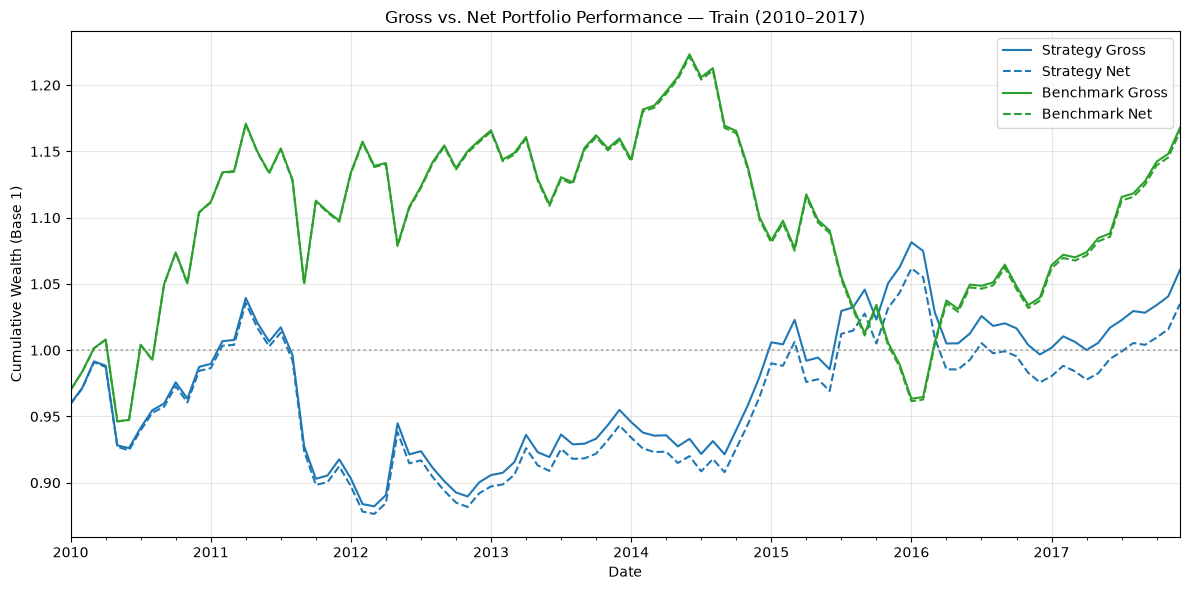

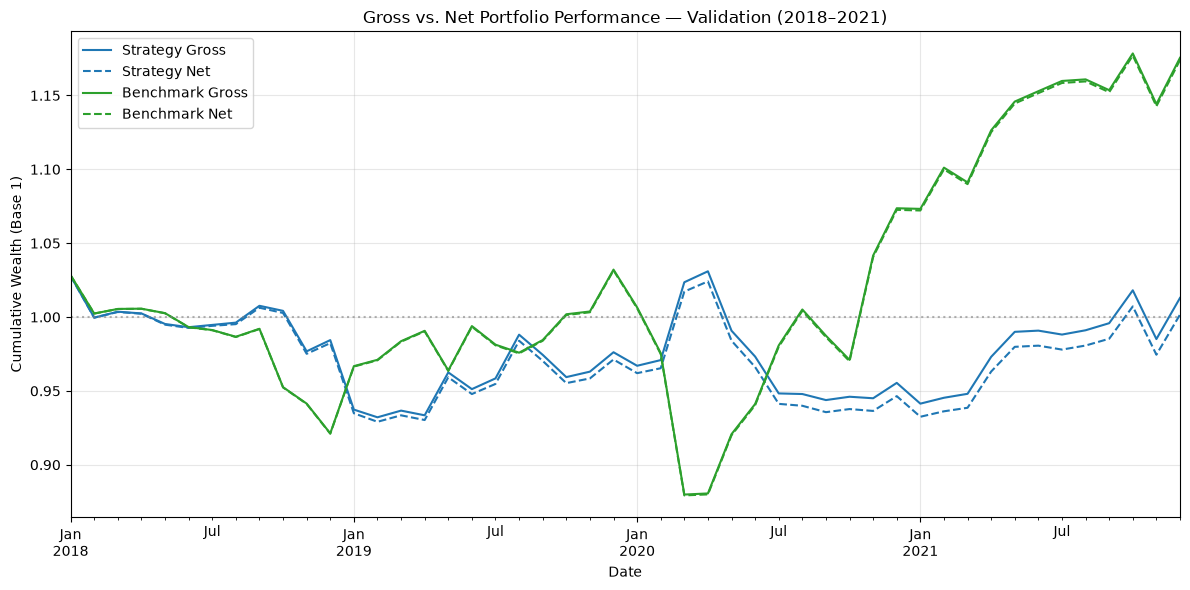

In [15]:
train_equity_curves = (1 + train_returns).cumprod()

validation_equity_curves = (1 + validation_returns).cumprod()

print(train_equity_curves.shape)
print(validation_equity_curves.shape)

ax = train_equity_curves.plot(figsize=(12,6), color=["tab:blue", "tab:blue", "tab:green", "tab:green"], style=["-", "--", "-", "--"])
ax.set_title("Gross vs. Net Portfolio Performance — Train (2010–2017)")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Wealth (Base 1)")
ax.axhline(y=1, color="grey", linestyle=":", alpha=0.6)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ay = validation_equity_curves.plot(figsize=(12,6), color=["tab:blue", "tab:blue", "tab:green", "tab:green"], style=["-", "--", "-", "--"])
ay.set_title("Gross vs. Net Portfolio Performance — Validation (2018–2021)")
ay.set_xlabel("Date")
ay.set_ylabel("Cumulative Wealth (Base 1)")
ay.axhline(y=1, color="grey", linestyle=":", alpha=0.6)
ay.legend()
ay.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Cost Sensitivity Analysis

Evaluate the sensitivity of strategy and benchmark
performance to alternative transaction cost assumptions.

The following cost scenarios are considered:

$$
c \in \{0, 0.0005, 0.001, 0.002, 0.005\}
$$

For each cost rate, net portfolio returns are calculated as:

$$
R_{p,t}^{net}(c) = R_{p,t}^{gross} - c \times TO_{p,t}
$$

Where:

- $c$: transaction cost rate.
- $TO_{p,t}$: actual monthly portfolio turnover.
- $R_{p,t}^{gross}$: gross monthly portfolio return.
- $R_{p,t}^{net}(c)$: net return under cost scenario $c$.

The objective is to assess the economic robustness
of the strategy under different trading cost assumptions.

The underlying signals and portfolio weights remain unchanged.

In [16]:
cost_scenarios = {
    "Frictionless" : 0.00000,
    "Low cost" : 0.0005,
    "Base case" : 0.0010,
    "High cost" : 0.0020,
    "Stress scenario" : 0.0050
    }

net_portfolio_returns_scenarios = {}

for scenario, rate in cost_scenarios.items():
    net_portfolio_returns_scenarios[scenario] = (gross_portfolio_returns - rate * actual_turnover).loc["2010":"2021"]

strategy_cost_sensitivity_returns = pd.DataFrame(net_portfolio_returns_scenarios)

display(strategy_cost_sensitivity_returns)
print(strategy_cost_sensitivity_returns.shape)

net_benchmark_returns_scenarios = {}

for scenario, rate in cost_scenarios.items():
    net_benchmark_returns_scenarios[scenario] = (benchmark_returns - rate * benchmark_actual_turnover).loc["2010":"2021"]

benchmark_cost_sensitivity_returns = pd.DataFrame(net_benchmark_returns_scenarios)

display(benchmark_cost_sensitivity_returns)
print(benchmark_cost_sensitivity_returns.shape)

print(np.allclose(
    strategy_cost_sensitivity_returns["Frictionless"],
    gross_portfolio_returns.loc["2010":"2021"]
))

net_portfolio_returns = gross_portfolio_returns - strategy_transaction_cost

print(np.allclose(
    strategy_cost_sensitivity_returns["Base case"],
    net_portfolio_returns.loc["2010":"2021"]
))

print(np.allclose(
    benchmark_cost_sensitivity_returns["Frictionless"],
    benchmark_returns.loc["2010":"2021"]
))

print(np.allclose(
    benchmark_cost_sensitivity_returns["Base case"],
    net_benchmark_returns.loc["2010":"2021"]
))

,Frictionless,Low cost,Base case,High cost,Stress scenario
Date,,,,,
2010-01-31,-0.040241,-0.040436,-0.040632,-0.041022,-0.042194
2010-02-28,0.012361,0.012341,0.012320,0.012279,0.012156
2010-03-31,0.020523,0.020388,0.020253,0.019984,0.019176
2010-04-30,-0.003259,-0.003395,-0.003531,-0.003804,-0.004622
2010-05-31,-0.060898,-0.060971,-0.061044,-0.061191,-0.061630
...,...,...,...,...,...
2021-08-31,0.002943,0.002871,0.002799,0.002655,0.002222
2021-09-30,0.004831,0.004762,0.004693,0.004555,0.004140
2021-10-31,0.022365,0.022288,0.022211,0.022057,0.021596


(144, 5)


,Frictionless,Low cost,Base case,High cost,Stress scenario
Date,,,,,
2010-01-31,-0.029985,-0.030000,-0.030015,-0.030046,-0.030137
2010-02-28,0.014269,0.014250,0.014230,0.014191,0.014074
2010-03-31,0.017951,0.017941,0.017931,0.017910,0.017849
2010-04-30,0.006469,0.006452,0.006434,0.006400,0.006296
2010-05-31,-0.061139,-0.061148,-0.061158,-0.061176,-0.061232
...,...,...,...,...,...
2021-08-31,0.000926,0.000918,0.000910,0.000894,0.000846
2021-09-30,-0.006289,-0.006296,-0.006303,-0.006317,-0.006359
2021-10-31,0.021550,0.021538,0.021525,0.021500,0.021424


(144, 5)
True
True
True
True


### 6.2 Performance Sensitivity Across Cost Scenarios

Evaluate performance and risk metrics under each
transaction cost scenario, separately for Train and Validation.

The analysis compares:

- Compound Annual Growth Rate (CAGR).
- Annualized Volatility.
- Sharpe Ratio.
- Maximum Drawdown.

All metrics are calculated using the reusable
`calculate_performance_metrics()` function.

The objective is to assess whether the strategy remains
economically viable as transaction costs increase.

In [17]:
train_strategy_cost_sensitivity_returns = strategy_cost_sensitivity_returns.loc["2010":"2017"]
train_benchmark_cost_sensitivity_returns = benchmark_cost_sensitivity_returns.loc["2010":"2017"]

validation_strategy_cost_sensitivity_returns = strategy_cost_sensitivity_returns.loc["2018":"2021"]
validation_benchmark_cost_sensitivity_returns = benchmark_cost_sensitivity_returns.loc["2018":"2021"]

train_strategy_sensitivity_metrics = {}

for scenario, returns in train_strategy_cost_sensitivity_returns.items():
    train_strategy_sensitivity_metrics[scenario] = calculate_performance_metrics(returns, risk_free_rate=0)

train_strategy_sensitivity_metrics_df = pd.DataFrame(train_strategy_sensitivity_metrics).T

display(train_strategy_sensitivity_metrics_df)
print(train_strategy_sensitivity_metrics_df.shape)

validation_strategy_sensitivity_metrics = {}

for scenario, returns in validation_strategy_cost_sensitivity_returns.items():
    validation_strategy_sensitivity_metrics[scenario] = calculate_performance_metrics(returns, risk_free_rate=0)

validation_strategy_sensitivity_metrics_df = pd.DataFrame(validation_strategy_sensitivity_metrics).T

display(validation_strategy_sensitivity_metrics_df)
print(validation_strategy_sensitivity_metrics_df.shape)

train_benchmark_sensitivity_metrics = {}

for scenario, returns in train_benchmark_cost_sensitivity_returns.items():
    train_benchmark_sensitivity_metrics[scenario] = calculate_performance_metrics(returns, risk_free_rate=0)

train_benchmark_sensitivity_metrics_df = pd.DataFrame(train_benchmark_sensitivity_metrics).T

display(train_benchmark_sensitivity_metrics_df)
print(train_benchmark_sensitivity_metrics_df.shape)

validation_benchmark_sensitivity_metrics = {}

for scenario, returns in validation_benchmark_cost_sensitivity_returns.items():
    validation_benchmark_sensitivity_metrics[scenario] = calculate_performance_metrics(returns, risk_free_rate=0)

validation_benchmark_sensitivity_metrics_df = pd.DataFrame(validation_benchmark_sensitivity_metrics).T

display(validation_benchmark_sensitivity_metrics_df)
print(validation_benchmark_sensitivity_metrics_df.shape)

,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Frictionless,0.007389,0.065697,0.144861,-0.151229
Low cost,0.005847,0.065711,0.121528,-0.152458
Base case,0.004308,0.065725,0.098203,-0.153687
High cost,0.001235,0.065759,0.051582,-0.156139
Stress scenario,-0.007934,0.065896,-0.087948,-0.166467


(5, 4)


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Frictionless,0.003218,0.065918,0.081015,-0.093109
Low cost,0.001815,0.065882,0.059782,-0.094580
Base case,0.000413,0.065849,0.038525,-0.096049
High cost,-0.002384,0.065787,-0.004054,-0.101276
Stress scenario,-0.010737,0.065646,-0.132184,-0.126447


(5, 4)


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Frictionless,0.019591,0.081578,0.278425,-0.212458
Low cost,0.019437,0.081578,0.276579,-0.212664
Base case,0.019284,0.081577,0.274732,-0.212870
High cost,0.018977,0.081575,0.271039,-0.213283
Stress scenario,0.018056,0.081570,0.259958,-0.214519


(5, 4)


,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
Frictionless,0.041250,0.096040,0.469095,-0.147531
Low cost,0.041084,0.096039,0.467427,-0.147576
Base case,0.040917,0.096037,0.465758,-0.147622
High cost,0.040583,0.096035,0.462421,-0.147714
Stress scenario,0.039584,0.096029,0.452407,-0.147988


(5, 4)


### 6.3 Cost Sensitivity Visualization

Visualize the sensitivity of portfolio performance to
increasing transaction costs across Train and Validation.

The analysis focuses on CAGR and Sharpe Ratio to assess
the economic robustness of the strategy relative to
the benchmark.

Frictionless       0.007389
Low cost           0.005847
Base case          0.004308
High cost          0.001235
Stress scenario   -0.007934
Name: CAGR, dtype: float64


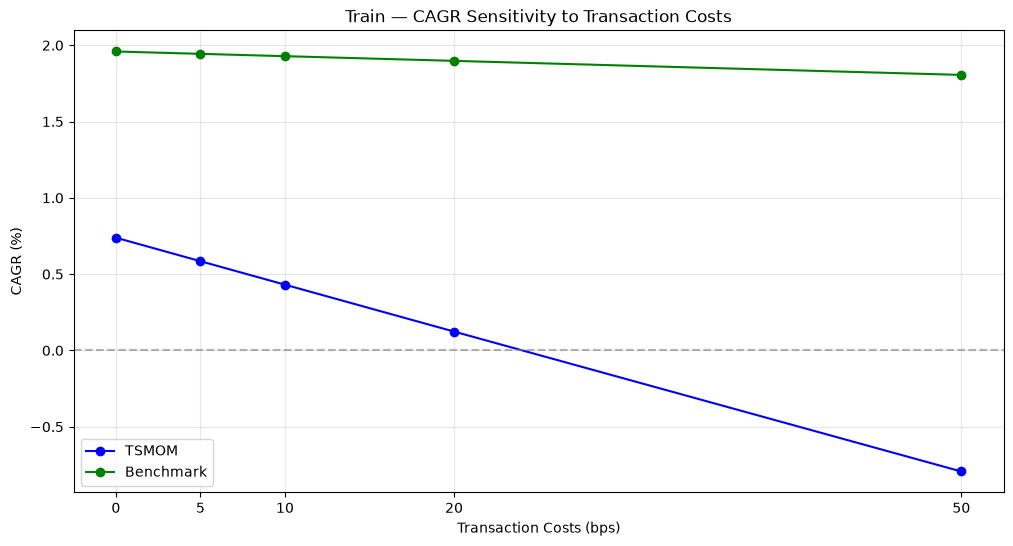

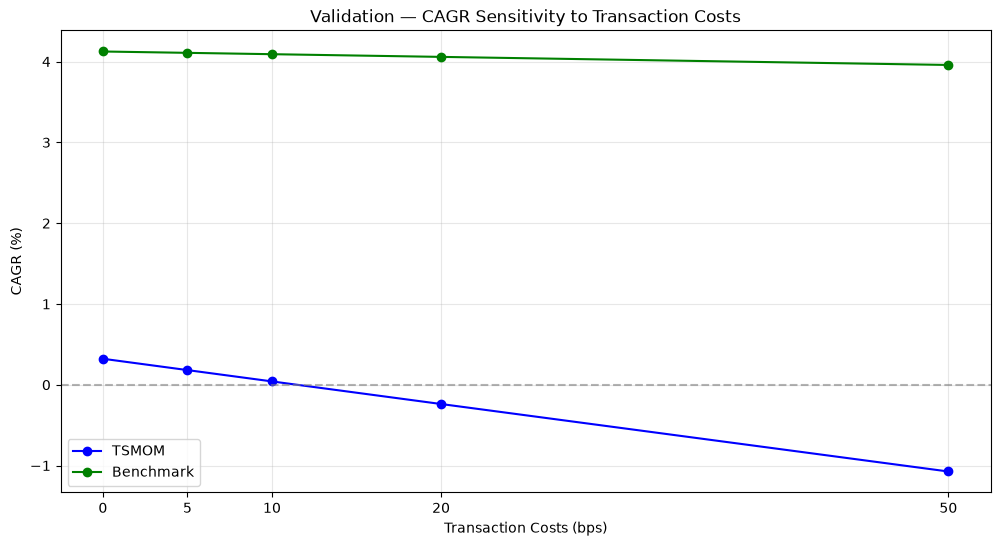

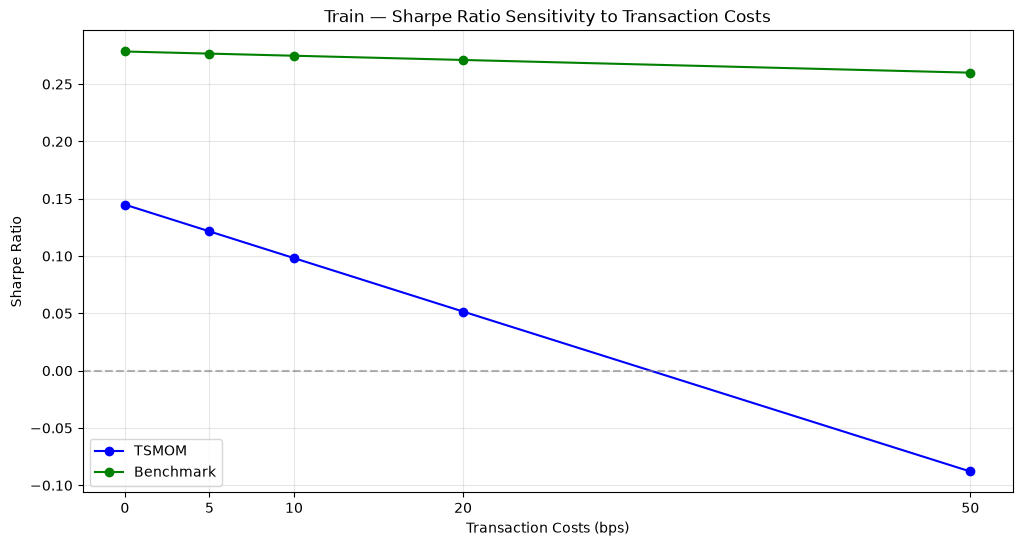

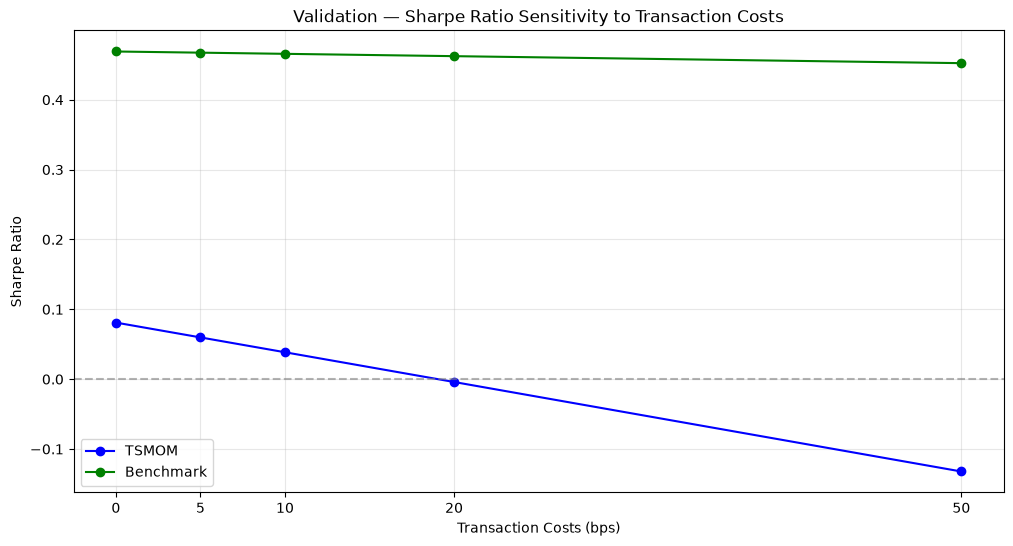

In [18]:
cost_bps = [cost * 10000 for cost in cost_scenarios.values()]

print(train_strategy_sensitivity_metrics_df["CAGR"])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cost_bps, train_strategy_sensitivity_metrics_df["CAGR"] * 100, label="TSMOM", color="blue", marker="o")
ax.plot(cost_bps, train_benchmark_sensitivity_metrics_df["CAGR"] * 100, label="Benchmark", color="green", marker="o")
ax.set_title("Train — CAGR Sensitivity to Transaction Costs")
ax.set_xlabel("Transaction Costs (bps)")
ax.set_ylabel("CAGR (%)")
ax.set_xticks(cost_bps)
ax.axhline(y=0, color="grey", linestyle="--", alpha=0.6)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

fig, ay = plt.subplots(figsize=(12, 6))
ay.plot(cost_bps, validation_strategy_sensitivity_metrics_df["CAGR"] * 100, label="TSMOM", color="blue", marker="o")
ay.plot(cost_bps, validation_benchmark_sensitivity_metrics_df["CAGR"] * 100, label="Benchmark", color="green", marker="o")
ay.set_title("Validation — CAGR Sensitivity to Transaction Costs")
ay.set_xlabel("Transaction Costs (bps)")
ay.set_ylabel("CAGR (%)")
ay.set_xticks(cost_bps)
ay.axhline(y=0, color="grey", linestyle="--", alpha=0.6)
ay.grid(alpha=0.3)
ay.legend()
plt.show()

fig, sa = plt.subplots(figsize=(12, 6))
sa.plot(cost_bps, train_strategy_sensitivity_metrics_df["Sharpe Ratio"], label="TSMOM", color="blue", marker="o")
sa.plot(cost_bps, train_benchmark_sensitivity_metrics_df["Sharpe Ratio"], label="Benchmark", color="green", marker="o")
sa.set_title("Train — Sharpe Ratio Sensitivity to Transaction Costs")
sa.set_xlabel("Transaction Costs (bps)")
sa.set_ylabel("Sharpe Ratio")
sa.set_xticks(cost_bps)
sa.axhline(y=0, color="grey", linestyle="--", alpha=0.6)
sa.grid(alpha=0.3)
sa.legend()
plt.show()

fig, sb = plt.subplots(figsize=(12, 6))
sb.plot(cost_bps, validation_strategy_sensitivity_metrics_df["Sharpe Ratio"], label="TSMOM", color="blue", marker="o")
sb.plot(cost_bps, validation_benchmark_sensitivity_metrics_df["Sharpe Ratio"], label="Benchmark", color="green", marker="o")
sb.set_title("Validation — Sharpe Ratio Sensitivity to Transaction Costs")
sb.set_xlabel("Transaction Costs (bps)")
sb.set_ylabel("Sharpe Ratio")
sb.set_xticks(cost_bps)
sb.axhline(y=0, color="grey", linestyle="--", alpha=0.6)
sb.grid(alpha=0.3)
sb.legend()
plt.show()

### 6.4 Break-even Transaction Cost

Estimate the transaction cost threshold at which
the strategy's net CAGR becomes zero.

$$
CAGR_{\text{net}}(c^*) = 0
$$

Using linear interpolation:

$$
c^* = c_1 - \frac{g_1}{g_2-g_1}(c_2-c_1)
$$

The objective is to quantify the strategy's tolerance
to transaction costs before losing absolute profitability.

In [30]:
c1 = cost_scenarios["High cost"] * 10000
c2 = cost_scenarios["Stress scenario"] * 10000

g1 = train_strategy_sensitivity_metrics_df.loc["High cost", "CAGR"]
g2 = train_strategy_sensitivity_metrics_df.loc["Stress scenario", "CAGR"]

train_break_even_cost = c1 - (g1 / (g2 - g1)) * (c2 - c1)

print(f"Train Break-even Cost : {train_break_even_cost:.2f} bps")

c3 = cost_scenarios["Base case"] * 10000

g3 = validation_strategy_sensitivity_metrics_df.loc["Base case", "CAGR"]
g4 = validation_strategy_sensitivity_metrics_df.loc["High cost", "CAGR"]

validation_break_even_cost = c3 - (g3 / (g4 - g3)) * (c1 - c3)

print(f"Validation Break-even Cost : {validation_break_even_cost:.2f} bps")

Train Break-even Cost : 24.04 bps
Validation Break-even Cost : 11.48 bps


#### 6.4.2 Break-even Cost Function — Implementation and Validation

The break-even transaction cost calculation has been generalized
into a reusable function, `calculate_break_even_cost()`,
implemented in `src/metrics.py`.

The function automatically:

- Sorts transaction cost scenarios in ascending order.
- Identifies consecutive scenarios surrounding a zero CAGR.
- Estimates the break-even cost using linear interpolation.
- Handles cases where the CAGR is exactly zero.
- Returns `None` when no break-even is identified within the
  tested cost range.

The function is imported and tested below on both Train and
Validation to verify consistency with the previous manual calculations.

All returned transaction cost thresholds are expressed in basis
points (bps).

In [44]:
importlib.reload(src.metrics)

from src.metrics import calculate_break_even_cost

train_break_even_cost_test = calculate_break_even_cost(train_strategy_sensitivity_metrics_df, cost_scenarios)
print(f"Train Break-even Cost Test : {train_break_even_cost_test:.2f} bps")

validation_break_even_cost_test = calculate_break_even_cost(validation_strategy_sensitivity_metrics_df, cost_scenarios)
print(f"Validation Break-even Cost Test : {validation_break_even_cost_test:.2f} bps")

print(np.isclose(train_break_even_cost_test, train_break_even_cost))
print(np.isclose(validation_break_even_cost_test, validation_break_even_cost))

Train Break-even Cost Test : 24.04 bps
Validation Break-even Cost Test : 11.48 bps
True
True


## 7. Research Conclusion

### Turnover and Transaction Costs

The TSMOM strategy exhibits an average annualized turnover of
297.62%, compared with 30.83% for the equally weighted benchmark.

Under the baseline transaction cost assumption of 10 bps,
this translates into estimated annual transaction costs of
29.76 bps for the strategy and 3.08 bps for the benchmark.

The higher turnover makes the TSMOM strategy substantially
more sensitive to transaction costs.

### Net Performance

| Metric | Train | Validation |
|---|---:|---:|
| Strategy Gross CAGR | 0.739% | 0.322% |
| Strategy Net CAGR | 0.431% | 0.041% |
| Strategy Gross Sharpe | 0.145 | 0.081 |
| Strategy Net Sharpe | 0.098 | 0.039 |
| Benchmark Net CAGR | 1.928% | 4.092% |
| Benchmark Net Sharpe | 0.275 | 0.466 |

Transaction costs reduce the strategy's CAGR by approximately
41.70% during Train and 87.15% during Validation.

Although the strategy exhibits lower volatility and smaller
maximum drawdowns than the benchmark, it underperforms in both
absolute and risk-adjusted terms.

### Cost Sensitivity and Break-even Analysis

The estimated break-even transaction costs are:

- Train: 24.04 bps.
- Validation: 11.48 bps.

The substantial reduction in the break-even threshold indicates
a deterioration in the strategy's ability to absorb transaction
costs during Validation.

At the baseline cost assumption of 10 bps, the strategy
retains only a marginally positive CAGR during Validation.

### Limitations

The transaction cost model assumes a constant proportional
cost per unit of traded notional. It does not explicitly account
for market impact, financing costs, short-selling fees or
additional execution frictions.

Furthermore, break-even thresholds are estimated through
linear interpolation rather than exact numerical optimization.

### Final Assessment

The current TSMOM implementation does not demonstrate sufficient
economic robustness under the tested assumptions.

Its limited gross profitability, high turnover and sensitivity
to transaction costs materially weaken its economic viability.

These findings do not invalidate Time-Series Momentum as a
general investment approach, but highlight the limitations
of this specific implementation.

Further research should investigate portfolio construction,
signal design and turnover reduction without introducing
parameter overfitting or data-snooping bias.

The Test sample remains untouched to preserve the integrity
of the final out-of-sample evaluation.